In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.colors as mcolors
import seaborn as sns
import torch
import pickle as pkl

from notebooks.evaluation_scores2csv import dataset_name
from src.model import Model

mpl.rcParams['text.usetex'] = True
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "Times New Roman"

fontsize= 27

colors = ["tab:red", "tab:blue"]

dict_keys(['filter_ratios', 'thresholds', 'recall', 'precision', 'f1'])
[125 124 124 123 123 123 121 120 119 117 115 112 110 109 108 105 104 104
 103 101]


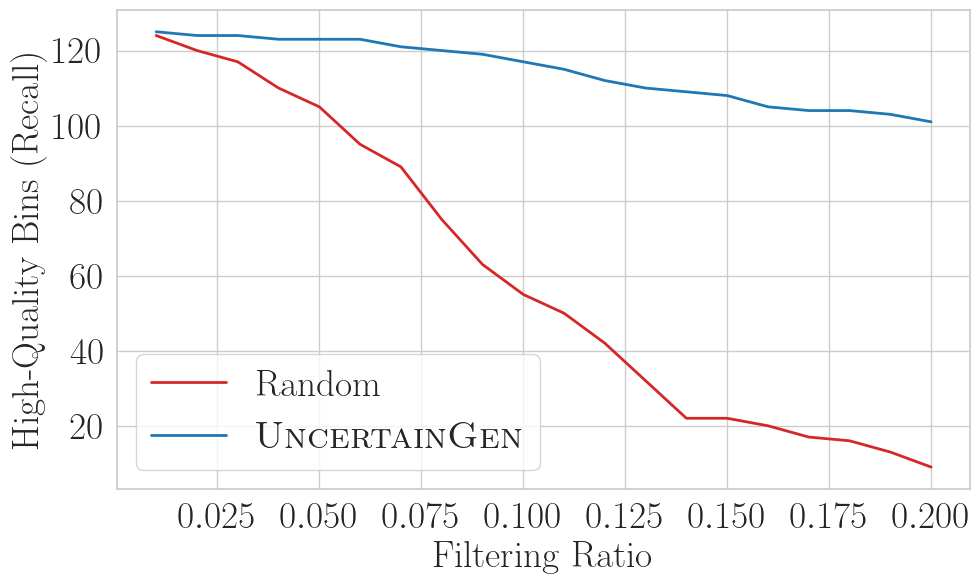

In [35]:

dataset_name = "reference"
dataset_ids = [5, 6]
ID = 5
strategies = ["random", "cov"]
model_name = f"model_k=4_d=256_negperpos=200_maxseq=100000_epoch=100_lr=0.001_batch=100000_loss=mahalanobis_strategy=var_only_seed=1_main_cpu_checkpoint.model.epoch_20.checkpoint_new_metric1_newfilter_{ID}"
file_path = f"../paper/filtering_results/{dataset_name}/{model_name}.pkl"

with open(file_path, 'rb') as f:
    results = pkl.load(f)

print(results['ours'][dataset_name][dataset_ids[0]][strategies[0]].keys())

# print(
#     results['ours'][dataset_name][dataset_ids[0]][strategies[0]]['recall']
# )

max_ratio_index = 20
filter_ratios = results['ours'][dataset_name][ID]["random"]['filter_ratios'][:max_ratio_index]
random_recall_scores = np.asarray(results['ours'][dataset_name][ID]["random"]['recall'])[:max_ratio_index,-1]
ours_recall_scores = np.asarray(results['ours'][dataset_name][ID]["cov"]['recall'])[:max_ratio_index, -1]

print(
    ours_recall_scores
)

plt.figure(figsize=(10, 6))
plt.plot(filter_ratios, random_recall_scores, label="Random", color=colors[0], linewidth=2)
plt.plot(filter_ratios, ours_recall_scores, label=r"\textsc{UncertainGen}", color=colors[1], linewidth=2)
plt.xlabel("Filtering Ratio", fontsize=fontsize)
plt.ylabel("High-Quality Bins (Recall)", fontsize=fontsize)
plt.xticks(fontsize=fontsize)
plt.yticks(fontsize=fontsize)
# plt.ylim(0, 1)
plt.legend(fontsize=fontsize)
plt.grid(True)
plt.tight_layout()
# plt.show()
plt.savefig("../paper/filtering_results_reference5.pdf", dpi=300, bbox_inches='tight')


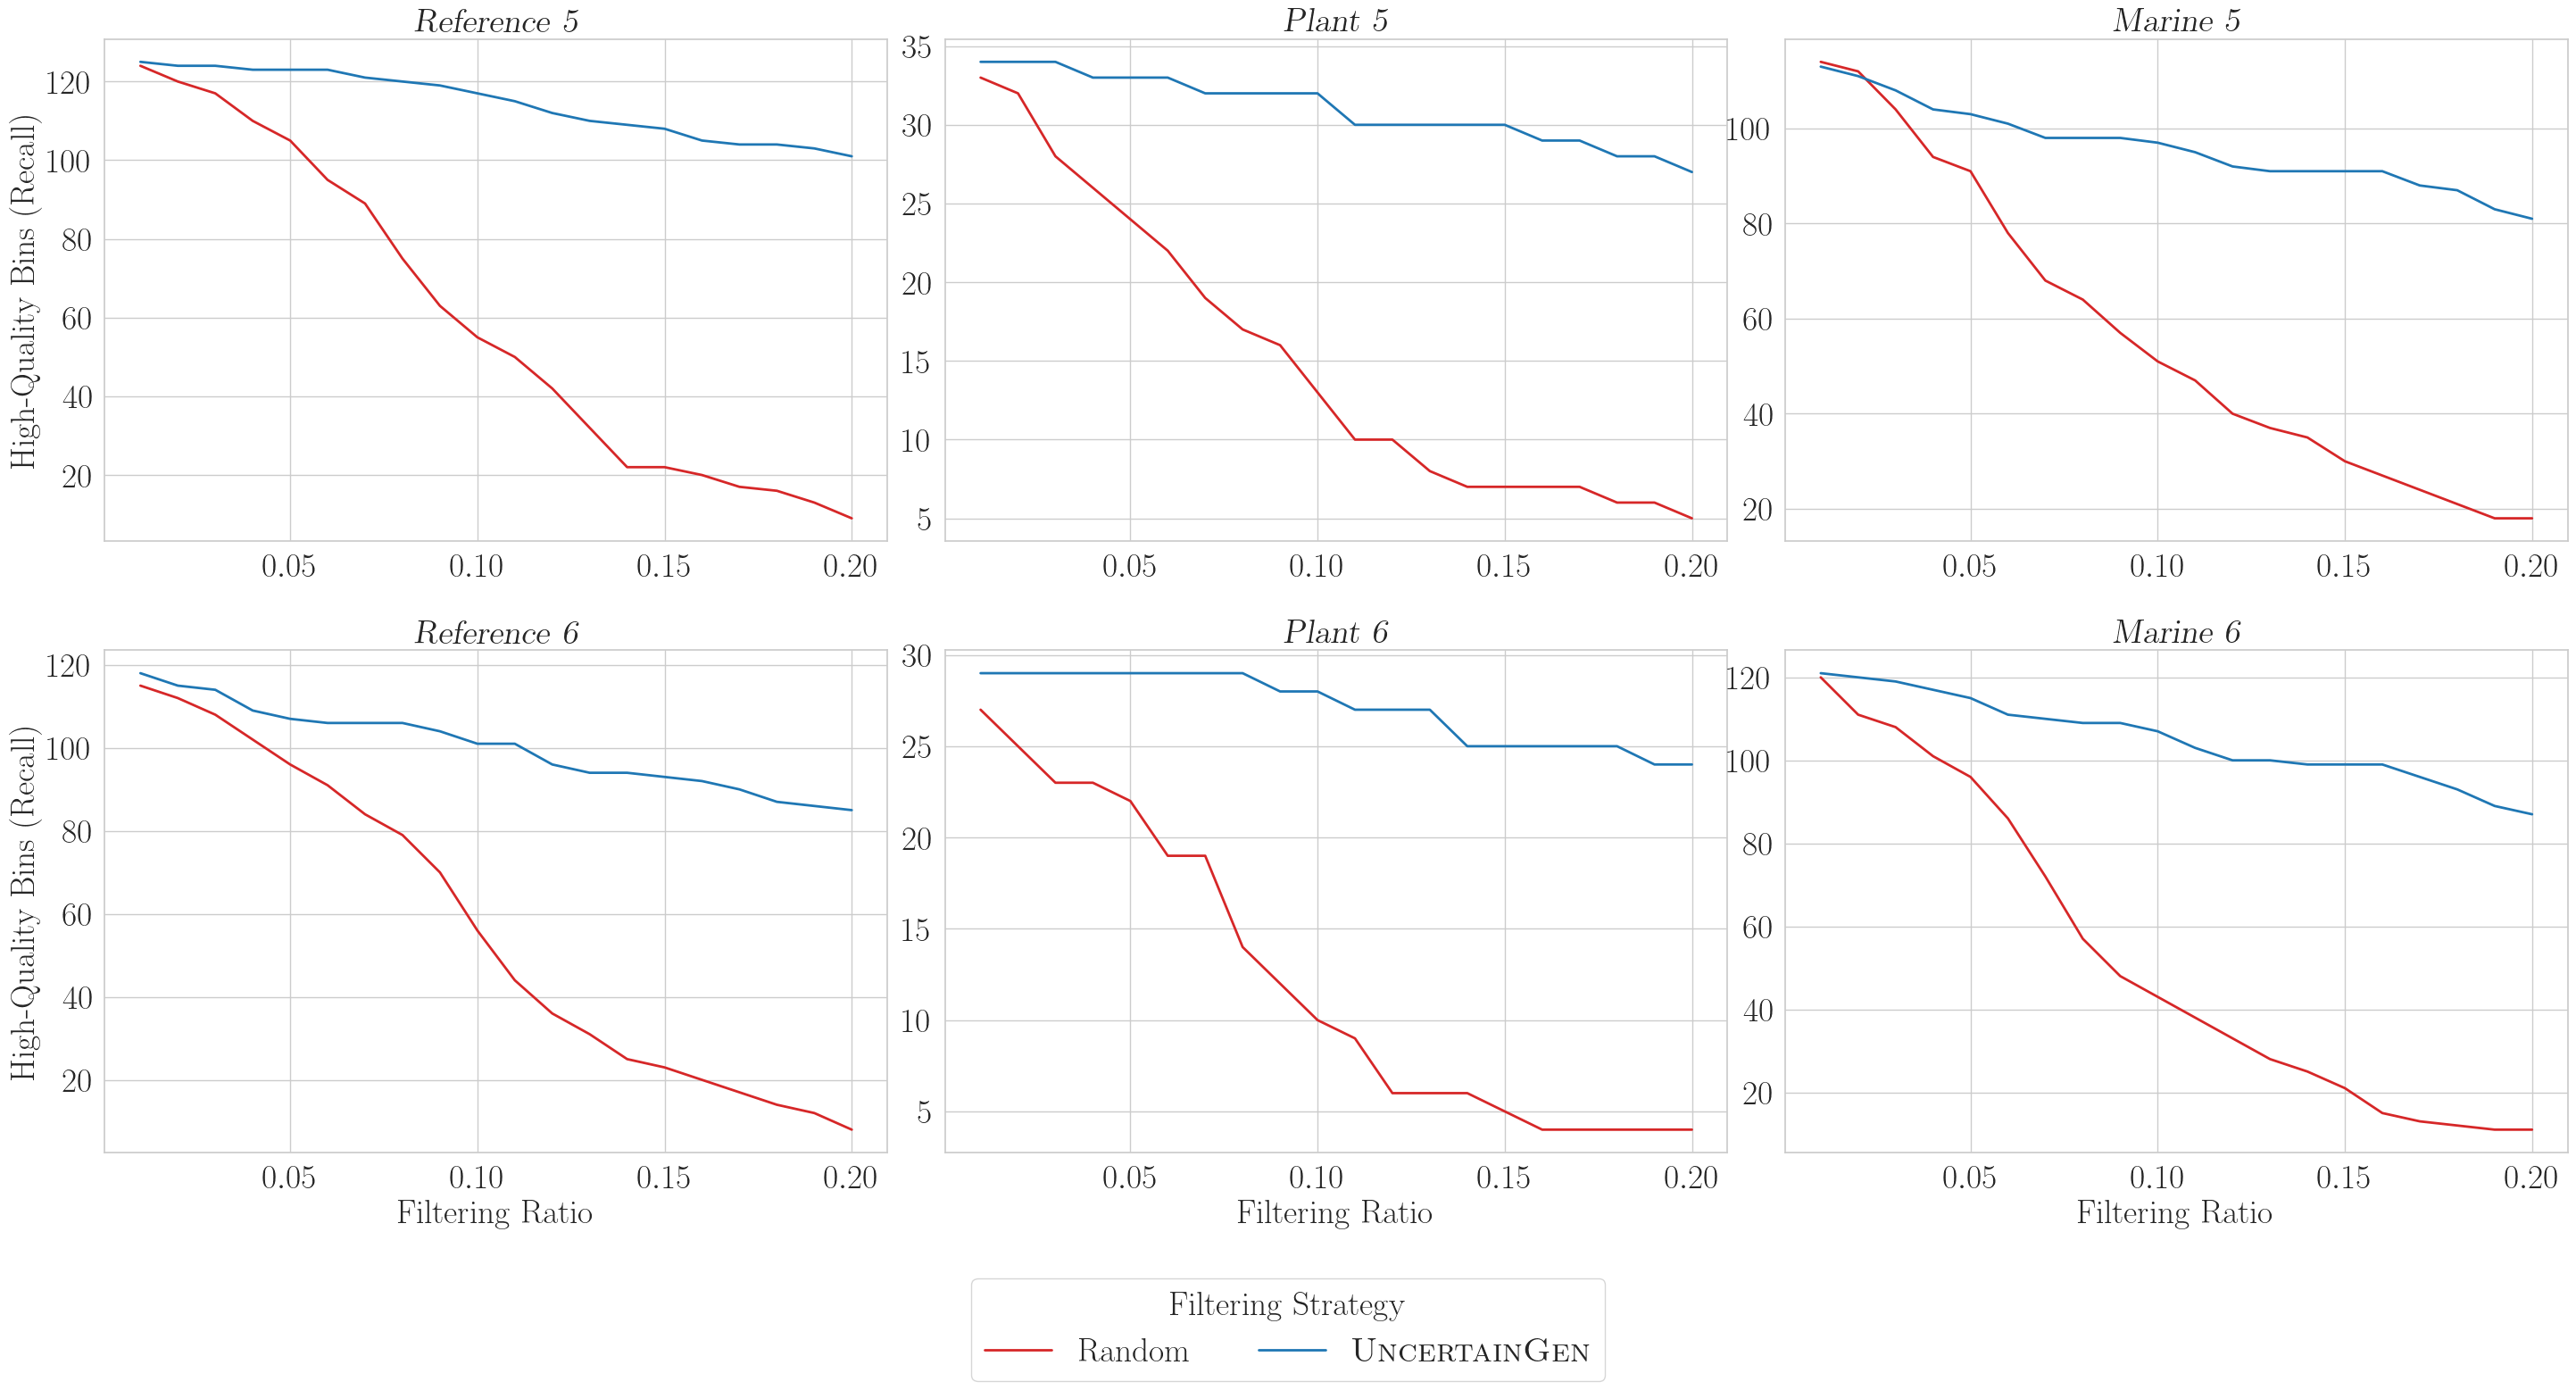

In [82]:
reference5_modelname = f"model_k=4_d=256_negperpos=200_maxseq=100000_epoch=100_lr=0.001_batch=100000_loss=mahalanobis_strategy=var_only_seed=1_main_cpu_checkpoint.model.epoch_20.checkpoint_new_metric1_newfilter_5"
reference5_path = f"../paper/filtering_results/reference/{reference5_modelname}.pkl"
reference6_modelname = f"model_k=4_d=256_negperpos=200_maxseq=100000_epoch=100_lr=0.001_batch=100000_loss=mahalanobis_strategy=var_only_seed=1_main_cpu_checkpoint.model.epoch_20.checkpoint_new_metric1_newfilter_6"
reference6_path = f"../paper/filtering_results/reference/{reference6_modelname}.pkl"
with open(reference5_path, 'rb') as f:
    reference5_results = pkl.load(f)
with open(reference6_path, 'rb') as f:
    reference6_results = pkl.load(f)

plant5_modelname = f"model_k=4_d=256_negperpos=200_maxseq=100000_epoch=100_lr=0.001_batch=100000_loss=mahalanobis_strategy=var_only_seed=1_main_cpu_checkpoint.model.epoch_20.checkpoint_new_metric1_newfilter_5"
plant5_path = f"../paper/filtering_results/plant/{plant5_modelname}.pkl"
plant6_modelname = f"model_k=4_d=256_negperpos=200_maxseq=100000_epoch=100_lr=0.001_batch=100000_loss=mahalanobis_strategy=var_only_seed=1_main_cpu_checkpoint.model.epoch_20.checkpoint_new_metric1_newfilter_6"
plant6_path = f"../paper/filtering_results/plant/{plant6_modelname}.pkl"

with open(plant5_path, 'rb') as f:
    plant5_results = pkl.load(f)
with open(plant6_path, 'rb') as f:
    plant6_results = pkl.load(f)


marine5_modelname = f"model_k=4_d=256_negperpos=200_maxseq=100000_epoch=100_lr=0.001_batch=100000_loss=mahalanobis_strategy=var_only_seed=1_main_cpu_checkpoint.model.epoch_20.checkpoint_new_metric1_newfilter_5"
marine5_path = f"../paper/filtering_results/marine/{marine5_modelname}.pkl"
marine6_modelname = f"model_k=4_d=256_negperpos=200_maxseq=100000_epoch=100_lr=0.001_batch=100000_loss=mahalanobis_strategy=var_only_seed=1_main_cpu_checkpoint.model.epoch_20.checkpoint_new_metric1_newfilter_6"
marine6_path = f"../paper/filtering_results/marine/{marine6_modelname}.pkl"

with open(marine5_path, 'rb') as f:
    marine5_results = pkl.load(f)
with open(marine6_path, 'rb') as f:
    marine6_results = pkl.load(f)


max_ratio_index = 20

# Plot the histograms side by side
fig, axes = plt.subplots(2, 3, figsize=(30, 15))

###
reference5_filter_ratios = reference5_results['ours']["reference"][5]["random"]['filter_ratios'][:max_ratio_index]
reference5_random_recall_scores = np.asarray(reference5_results['ours']["reference"][5]["random"]['recall'])[:max_ratio_index,-1]
reference5_ours_recall_scores = np.asarray(reference5_results['ours']["reference"][5]["cov"]['recall'])[:max_ratio_index, -1]
###
axes[0, 0].plot(reference5_filter_ratios, reference5_random_recall_scores, label="Random", color=colors[0], linewidth=2)
axes[0, 0].plot(reference5_filter_ratios, reference5_ours_recall_scores, label=r"$\textsc{UncertainGen}$", color=colors[1], linewidth=2)
axes[0, 0].set_title(r"$\textsl{Reference 5}$", fontsize=fontsize)
# axes[0, 0].set_xlabel("Filtering Ratio", fontsize=fontsize)
axes[0, 0].set_ylabel("High-Quality Bins (Recall)", fontsize=fontsize)
axes[0, 0].tick_params(axis='x', labelsize=fontsize)
axes[0, 0].tick_params(axis='y', labelsize=fontsize)
# axes[0, 0].legend(fontsize=fontsize)
axes[0, 0].grid(True)


###
plant5_filter_ratios = plant5_results['ours']["plant"][5]["random"]['filter_ratios'][:max_ratio_index]
plant5_random_recall_scores = np.asarray(plant5_results['ours']["plant"][5]["random"]['recall'])[:max_ratio_index,-1]
plant5_ours_recall_scores = np.asarray(plant5_results['ours']["plant"][5]["cov"]['recall'])[:max_ratio_index, -1]
###
axes[0, 1].plot(reference5_filter_ratios, plant5_random_recall_scores, label="Random", color=colors[0], linewidth=2)
axes[0, 1].plot(reference5_filter_ratios, plant5_ours_recall_scores, label=r"$\textsc{UncertainGen}$", color=colors[1], linewidth=2)
axes[0, 1].set_title(r"$\textsl{Plant 5}$", fontsize=fontsize)
# axes[0, 0].set_xlabel("Filtering Ratio", fontsize=fontsize)
# axes[0, 1].set_ylabel("High-Quality Bins (Recall)", fontsize=fontsize)
axes[0, 1].tick_params(axis='x', labelsize=fontsize)
axes[0, 1].tick_params(axis='y', labelsize=fontsize)
# axes[0, 1].legend(fontsize=fontsize)
axes[0, 1].grid(True)


###
marine5_filter_ratios = marine5_results['ours']["marine"][5]["random"]['filter_ratios'][:max_ratio_index]
marine5_random_recall_scores = np.asarray(marine5_results['ours']["marine"][5]["random"]['recall'])[:max_ratio_index,-1]
marine5_ours_recall_scores = np.asarray(marine5_results['ours']["marine"][5]["cov"]['recall'])[:max_ratio_index, -1]
###
axes[0, 2].plot(marine5_filter_ratios, marine5_random_recall_scores, label="Random", color=colors[0], linewidth=2)
axes[0, 2].plot(marine5_filter_ratios, marine5_ours_recall_scores, label=r"$\textsc{UncertainGen}$", color=colors[1], linewidth=2)
axes[0, 2].set_title(r"$\textsl{Marine 5}$", fontsize=fontsize)
# axes[0, 0].set_xlabel("Filtering Ratio", fontsize=fontsize)
# axes[0, 1].set_ylabel("High-Quality Bins (Recall)", fontsize=fontsize)
axes[0, 2].tick_params(axis='x', labelsize=fontsize)
axes[0, 2].tick_params(axis='y', labelsize=fontsize)
# axes[0, 2].legend(fontsize=fontsize)
axes[0, 2].grid(True)


###
reference6_filter_ratios = reference6_results['ours']["reference"][6]["random"]['filter_ratios'][:max_ratio_index]
reference6_random_recall_scores = np.asarray(reference6_results['ours']["reference"][6]["random"]['recall'])[:max_ratio_index,-1]
reference6_ours_recall_scores = np.asarray(reference6_results['ours']["reference"][6]["cov"]['recall'])[:max_ratio_index, -1]
###
axes[1, 0].plot(reference6_filter_ratios, reference6_random_recall_scores, label="Random", color=colors[0], linewidth=2)
axes[1, 0].plot(reference6_filter_ratios, reference6_ours_recall_scores, label=r"$\textsc{UncertainGen}$", color=colors[1], linewidth=2)
axes[1, 0].set_title(r"$\textsl{Reference 6}$", fontsize=fontsize)
axes[1, 0].set_xlabel("Filtering Ratio", fontsize=fontsize)
axes[1, 0].set_ylabel("High-Quality Bins (Recall)", fontsize=fontsize)
axes[1, 0].tick_params(axis='x', labelsize=fontsize)
axes[1, 0].tick_params(axis='y', labelsize=fontsize)
# axes[1, 0].legend(fontsize=fontsize)
axes[1, 0].grid(True)

###
plant6_filter_ratios = plant6_results['ours']["plant"][6]["random"]['filter_ratios'][:max_ratio_index]
plant6_random_recall_scores = np.asarray(plant6_results['ours']["plant"][6]["random"]['recall'])[:max_ratio_index,-1]
plant6_ours_recall_scores = np.asarray(plant6_results['ours']["plant"][6]["cov"]['recall'])[:max_ratio_index, -1]
###
axes[1, 1].plot(plant6_filter_ratios, plant6_random_recall_scores, label="Random", color=colors[0], linewidth=2)
axes[1, 1].plot(plant6_filter_ratios, plant6_ours_recall_scores, label=r"$\textsc{UncertainGen}$", color=colors[1], linewidth=2)
axes[1, 1].set_title(r"$\textsl{Plant 6}$", fontsize=fontsize)
axes[1, 1].set_xlabel("Filtering Ratio", fontsize=fontsize)
# axes[1, 1].set_ylabel("High-Quality Bins (Recall)", fontsize=fontsize)
axes[1, 1].tick_params(axis='x', labelsize=fontsize)
axes[1, 1].tick_params(axis='y', labelsize=fontsize)
# axes[1, 1].legend(fontsize=fontsize)
axes[1, 1].grid(True)

###
marine6_filter_ratios = marine6_results['ours']["marine"][6]["random"]['filter_ratios'][:max_ratio_index]
marine6_random_recall_scores = np.asarray(marine6_results['ours']["marine"][6]["random"]['recall'])[:max_ratio_index,-1]
marine6_ours_recall_scores = np.asarray(marine6_results['ours']["marine"][6]["cov"]['recall'])[:max_ratio_index, -1]
###
axes[1, 2].plot(marine6_filter_ratios, marine6_random_recall_scores, label="Random", color=colors[0], linewidth=2)
axes[1, 2].plot(marine6_filter_ratios, marine6_ours_recall_scores, label=r"$\textsc{UncertainGen}$", color=colors[1], linewidth=2)
axes[1, 2].set_title(r"$\textsl{Marine 6}$", fontsize=fontsize)
axes[1, 2].set_xlabel("Filtering Ratio", fontsize=fontsize)
# axes[1, 1].set_ylabel("High-Quality Bins (Recall)", fontsize=fontsize)
axes[1, 2].tick_params(axis='x', labelsize=fontsize)
axes[1, 2].tick_params(axis='y', labelsize=fontsize)
# axes[1, 1].legend(fontsize=fontsize)
axes[1, 2].grid(True)

# Add the legend out of the plot and below in one line
legend = fig.legend(
    ["Random", r"$\textsc{UncertainGen}$"],
    loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=5, fontsize=fontsize
)
# Add legend title
legend.set_title("Filtering Strategy", prop={'size': fontsize})
plt.tight_layout(w_pad=0., h_pad=2.5, pad=4)

# plt.show()
plt.savefig("../paper/filtering_results_all.pdf", dpi=300, bbox_inches='tight')
